In [1]:
# Imports
import pandas as pd
import seaborn as sns
import pickle 
import settings

from sklearn.model_selection import train_test_split
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score

climate_data = pd.read_csv(settings.TRAINING_DATA_PATH)


In [2]:
# Get idea about dataset
climate_data.shape


(699, 11)

In [3]:
# Get idea about dataset
climate_data.describe()

,t_inside,h_inside,t_outside,h_outside,prev_t_inside,prev_h_inside,prev_t_outside,prev_h_outside,fanTargetSpeed
count,699.000000,699.000000,699.000000,699.000000,699.000000,699.000000,699.000000,699.000000,699.000000
mean,24.741202,59.902146,24.605007,59.747497,24.738340,59.903577,24.602432,59.750930,62.655222
std,1.293677,3.784569,1.311342,3.649780,1.299191,3.784227,1.315788,3.648697,21.369244
min,21.200001,50.799999,21.500000,50.599998,21.200001,50.799999,21.500000,50.599998,0.000000
25%,23.600000,56.950001,23.500000,56.950001,23.600000,56.950001,23.500000,56.950001,45.000000
50%,25.100000,60.700001,25.000000,60.700001,25.100000,60.700001,25.000000,60.700001,63.000000
75%,25.799999,62.200001,25.700001,61.900002,25.799999,62.200001,25.700001,61.900002,81.500000
max,27.100000,68.599998,26.700001,68.099998,27.100000,68.599998,26.700001,68.099998,99.000000


In [4]:
# Prepare data (defining x and y)
climate_data['Heating'] = climate_data['Heating'].astype(bool)
inputSet = climate_data.drop(columns=['t_inside', 'h_inside', 'timestamp'])
outputSet = climate_data[['t_inside', 'h_inside']]

In [5]:
# Splitting Data into train- and testdata
input_train, input_test, output_train, output_test = train_test_split(inputSet, outputSet, test_size=0.2)
input_train.shape, output_train.shape, input_test.shape, output_test.shape

((559, 8), (559, 2), (140, 8), (140, 2))

In [6]:
# Create Model
model = linear_model.LinearRegression()
model.fit(input_train, output_train)

LinearRegression()

In [7]:
# Make Predictions
test_predictions = model.predict(input_test)

In [8]:
# Model Performance

model_mse = mean_squared_error(output_test, test_predictions)
model_r2_score = r2_score(output_test, test_predictions)
score = model.score(input_test, output_test)

print("Score: ", score)
print("Coefficients: ", model.coef_)
print("Intercept: ", model.intercept_)
print("Mean squared error (MSE): ", model_mse)
print("Coefficient of determination (R^2): ", model_r2_score)
#print("Mean absolute error (MEA): ", model.mea)

Score:  0.9956861718841655
Coefficients:  [[ 6.67992896e-01 -4.03191248e-02  5.97371011e-01 -3.38640746e-02
  -2.71719264e-01  7.40537117e-02 -3.52634637e-05 -9.40431140e-03]
 [-3.59207500e-01  7.70070438e-01 -8.93241751e-01  6.71834792e-01
   1.26785116e+00 -4.36775012e-01 -4.65778379e-04  7.25738838e-03]]
Intercept:  [ 0.23214144 -0.47621097]
Mean squared error (MSE):  0.02854660657727798
Coefficient of determination (R^2):  0.9956861718841655


In [9]:
model.predict([[20.10000038, 49.5, 19.10000038, 54.29999924, 20, 49.59999847, 32, False]])


array([[19.4715198 , 53.51999416]])

<AxesSubplot:xlabel='t_inside'>

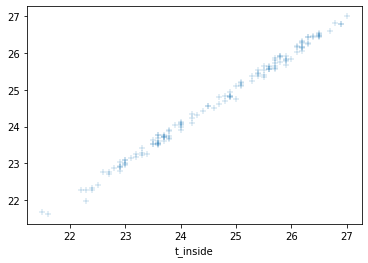

In [10]:
# Create Plots


test_t = output_test["t_inside"]
test_h = output_test["h_inside"]
predicted_t = test_predictions[:,0]
predicted_h = test_predictions[:,1]

# temperature
sns.scatterplot(x = test_t, y = predicted_t, marker="+", alpha=0.5 )

<AxesSubplot:xlabel='h_inside'>

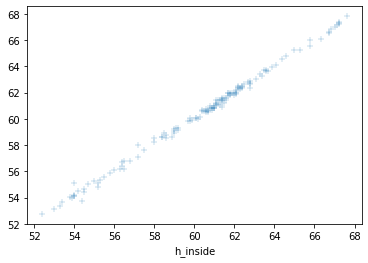

In [11]:
# humidity
sns.scatterplot(x=test_h, y = predicted_h, marker="+", alpha=0.5)

In [12]:
pkl_filename = settings.TRAINED_MODEL_PATH
with open(pkl_filename, 'wb') as file:
    pickle.dump(model, file)